# Hospital heart disease task — binary classification

**Goal:** predict whether a patient has heart disease (`heart_disease` = 1) from 10 risk factors.

**Dataset:** `hospital_synthetic_dataset.xlsx` (from the course Google Drive, *Assignments → Hospital heart disease task*).

**What this notebook covers (same flow as the class ROC/AUC tutorial):**
1. Load and explore the data (EDA)
2. Preprocess: encode Yes/No and Male/Female, split train/test, scale
3. Train 3 models: Logistic Regression, Random Forest, Gradient Boosting
4. Evaluate: confusion matrix, accuracy, precision, recall, F1
5. ROC curve and AUC for all models
6. Threshold tuning
7. What the results mean

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score, accuracy_score)
RANDOM_STATE = 42
df = pd.read_excel('../data/hospital_synthetic_dataset.xlsx')
print(df.shape)
df.head()

(500, 11)


,age,sex,blood_pressure,cholesterol,bmi,smoker,diabetes,physical_activity,family_history,stress_level,heart_disease
0,68,Male,105,191,38.0,Yes,Yes,0,No,2,0
1,58,Female,97,249,22.0,Yes,Yes,0,No,4,0
2,44,Female,93,190,23.2,No,Yes,0,No,8,0
3,72,Male,93,183,39.4,No,No,3,Yes,1,0
4,37,Female,145,166,22.0,No,Yes,4,Yes,1,0


## 1. Explore the data

In [2]:
df.info()
print('\nMissing values per column:\n', df.isna().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                500 non-null    int64  
 1   sex                500 non-null    str    
 2   blood_pressure     500 non-null    int64  
 3   cholesterol        500 non-null    int64  
 4   bmi                500 non-null    float64
 5   smoker             500 non-null    str    
 6   diabetes           500 non-null    str    
 7   physical_activity  500 non-null    int64  
 8   family_history     500 non-null    str    
 9   stress_level       500 non-null    int64  
 10  heart_disease      500 non-null    int64  
dtypes: float64(1), int64(6), str(4)
memory usage: 43.1 KB

Missing values per column:
 age                  0
sex                  0
blood_pressure       0
cholesterol          0
bmi                  0
smoker               0
diabetes             0
physical_activity    0
family_his

,count,mean,std,min,25%,50%,75%,max
age,500.0,54.8640,14.315004,30.0,43.000,55.0,66.250,79.0
blood_pressure,500.0,132.8740,26.418516,90.0,111.000,132.0,155.000,179.0
cholesterol,500.0,221.5000,43.863630,150.0,183.750,221.0,258.000,299.0
bmi,500.0,29.0204,6.400954,18.1,23.275,29.2,34.525,40.0
physical_activity,500.0,2.0480,1.421879,0.0,1.000,2.0,3.000,4.0
stress_level,500.0,4.8760,2.595013,1.0,3.000,5.0,7.000,9.0
heart_disease,500.0,0.5320,0.499475,0.0,0.000,1.0,1.000,1.0


heart_disease
1    266
0    234
Name: count, dtype: int64
Share with heart disease: 53.2%


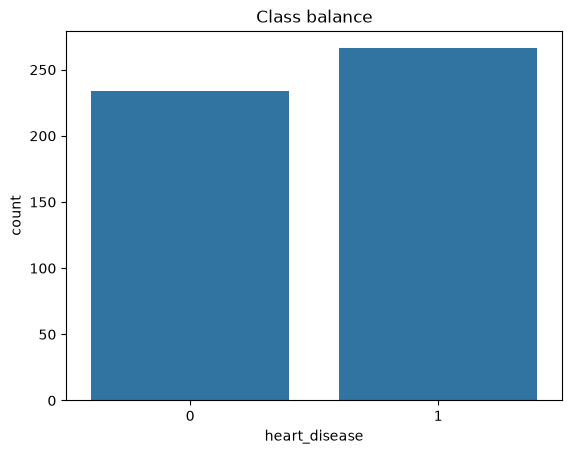

In [3]:
print(df['heart_disease'].value_counts())
print('Share with heart disease: %.1f%%' % (100 * df['heart_disease'].mean()))
sns.countplot(x='heart_disease', data=df); plt.title('Class balance'); plt.show()

**Class balance matters:** if one class were 90% of the data, a model could score 90% accuracy by always guessing it. That is why we also look at recall, precision and AUC, not only accuracy.

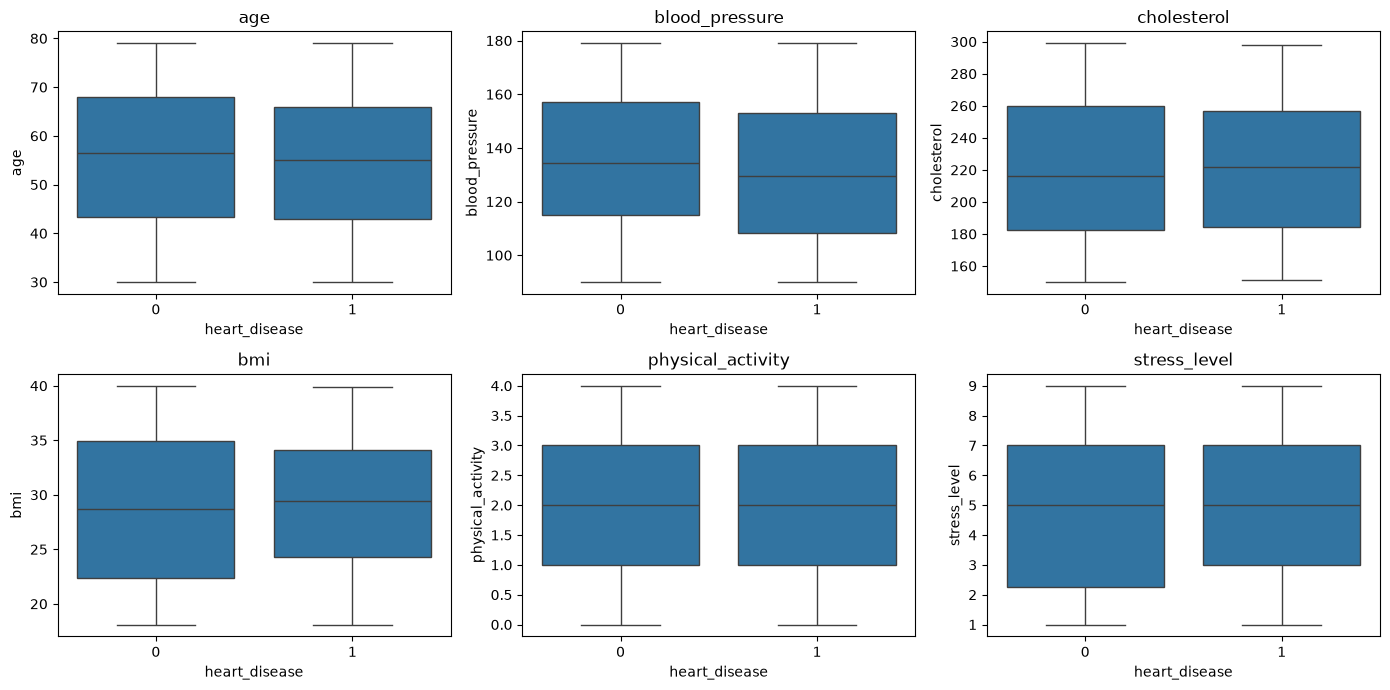

In [4]:
num_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi', 'physical_activity', 'stress_level']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x='heart_disease', y=c, data=df, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

In [5]:
cat_cols = ['sex', 'smoker', 'diabetes', 'family_history']
for c in cat_cols:
    print(pd.crosstab(df[c], df['heart_disease'], normalize='index').round(2), '\n')

heart_disease     0     1
sex                      
Female         0.48  0.52
Male           0.45  0.55 

heart_disease     0     1
smoker                   
No             0.52  0.48
Yes            0.42  0.58 

heart_disease     0     1
diabetes                 
No             0.46  0.54
Yes            0.48  0.52 

heart_disease      0     1
family_history            
No              0.47  0.53
Yes             0.47  0.53 



## 2. Preprocess
Yes/No → 1/0, Male → 1, Female → 0. Then a stratified 80/20 train/test split (stratified = both sets keep the same share of heart-disease cases).

train (400, 10) test (100, 10)


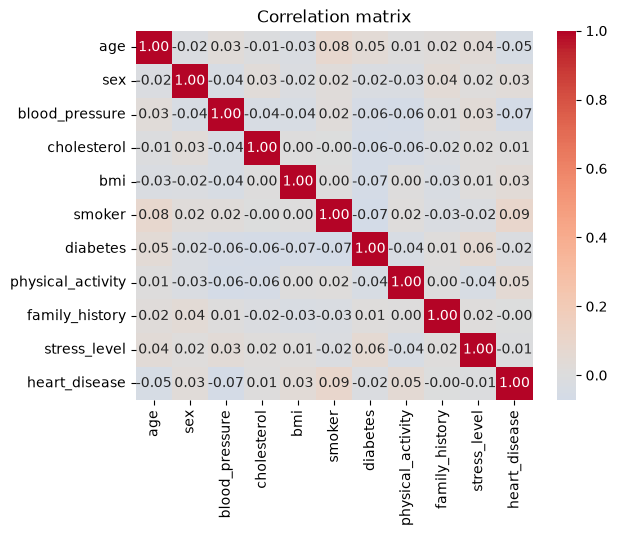

In [6]:
data = df.copy()
for c in ['smoker', 'diabetes', 'family_history']:
    data[c] = data[c].map({'Yes': 1, 'No': 0})
data['sex'] = data['sex'].map({'Male': 1, 'Female': 0})
X = data.drop(columns='heart_disease'); y = data['heart_disease']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('train', X_train.shape, 'test', X_test.shape)
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Correlation matrix'); plt.show()

## 3. Train three models
Logistic Regression needs scaled features (so it sits in a pipeline with `StandardScaler`). Tree models do not need scaling.

In [7]:
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}
probs = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    probs[name] = m.predict_proba(X_test)[:, 1]
    pred = (probs[name] >= 0.5).astype(int)
    print(f'===== {name} =====')
    print('Accuracy: %.3f   AUC: %.3f' % (accuracy_score(y_test, pred), roc_auc_score(y_test, probs[name])))
    print(classification_report(y_test, pred, digits=3))

===== Logistic Regression =====
Accuracy: 0.560   AUC: 0.505
              precision    recall  f1-score   support

           0      0.556     0.319     0.405        47
           1      0.562     0.774     0.651        53

    accuracy                          0.560       100
   macro avg      0.559     0.546     0.528       100
weighted avg      0.559     0.560     0.535       100



===== Random Forest =====
Accuracy: 0.530   AUC: 0.565
              precision    recall  f1-score   support

           0      0.500     0.468     0.484        47
           1      0.554     0.585     0.569        53

    accuracy                          0.530       100
   macro avg      0.527     0.526     0.526       100
weighted avg      0.528     0.530     0.529       100

===== Gradient Boosting =====
Accuracy: 0.550   AUC: 0.542
              precision    recall  f1-score   support

           0      0.528     0.404     0.458        47
           1      0.562     0.679     0.615        53

    accuracy                          0.550       100
   macro avg      0.545     0.542     0.537       100
weighted avg      0.546     0.550     0.541       100



## 4. Confusion matrices
|                | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | TN (true negative) | FP (false positive — healthy person flagged) |
| **Actual 1** | FN (false negative — sick person missed) | TP (true positive) |

In medicine a **false negative is usually the worst mistake** (a sick patient sent home), so **recall** (TP / (TP+FN)) is important.

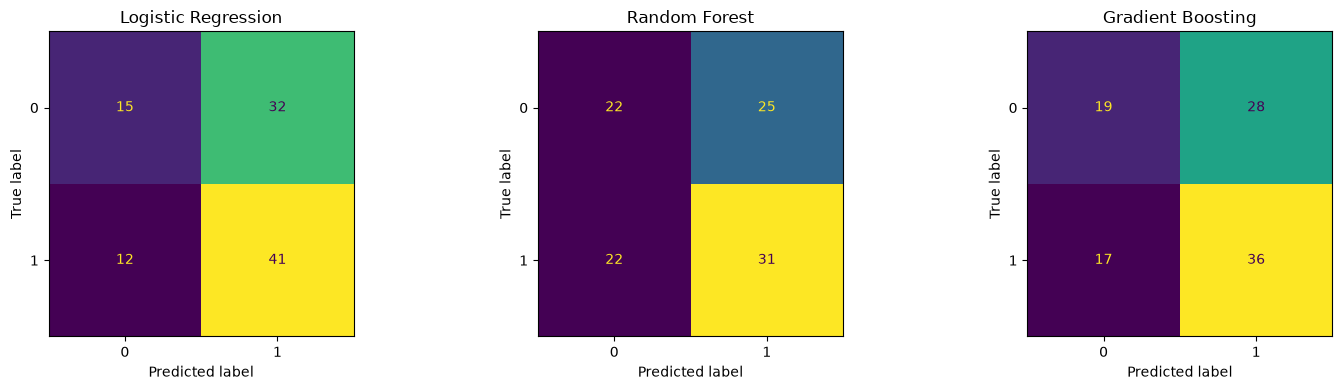

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= 0.5).astype(int))).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 5. ROC curves and AUC
The ROC curve plots **TPR (recall)** against **FPR** for every threshold. **AUC** = area under it: 1.0 is perfect, **0.5 is no better than a coin flip** (the dashed diagonal).

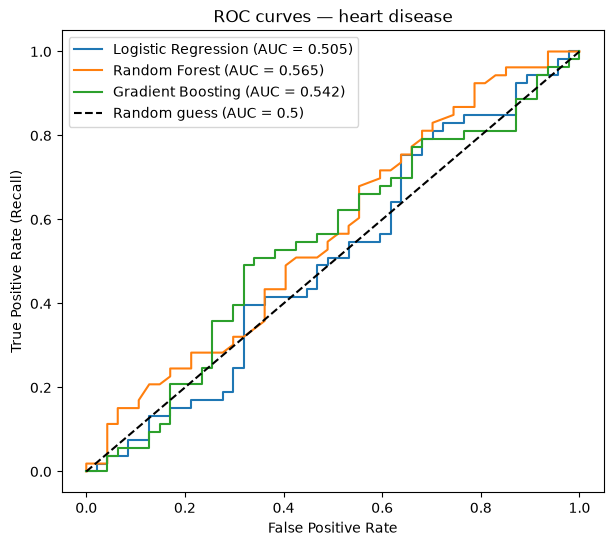

In [9]:
plt.figure(figsize=(7, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)'); plt.title('ROC curves — heart disease')
plt.legend(); plt.show()

## 6. Cross-validation (a fairer check than one split)
With only ~100 test patients, one split can be lucky or unlucky. 5-fold cross-validation trains and tests 5 times on different parts of the data.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=cv, scoring='roc_auc')
    print(f'{name:20s} AUC = {s.mean():.3f} ± {s.std():.3f}')

Logistic Regression  AUC = 0.507 ± 0.053


Random Forest        AUC = 0.495 ± 0.077


Gradient Boosting    AUC = 0.541 ± 0.095


## 7. Threshold tuning
The default rule is "predict 1 if probability ≥ 0.5". Lowering the threshold catches more sick patients (higher recall) but raises false alarms.

In [11]:
p = probs['Logistic Regression']
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    tn, fp, fn, tp = confusion_matrix(y_test, (p >= t).astype(int)).ravel()
    rows.append({'threshold': t, 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
                 'recall': tp / (tp + fn), 'false_positive_rate': fp / (fp + tn)})
pd.DataFrame(rows).round(3)

,threshold,TP,FN,FP,TN,recall,false_positive_rate
0,0.3,53,0,47,0,1.000,1.000
1,0.4,52,1,45,2,0.981,0.957
2,0.5,41,12,32,15,0.774,0.681
3,0.6,7,46,7,40,0.132,0.149
4,0.7,0,53,1,46,0.000,0.021


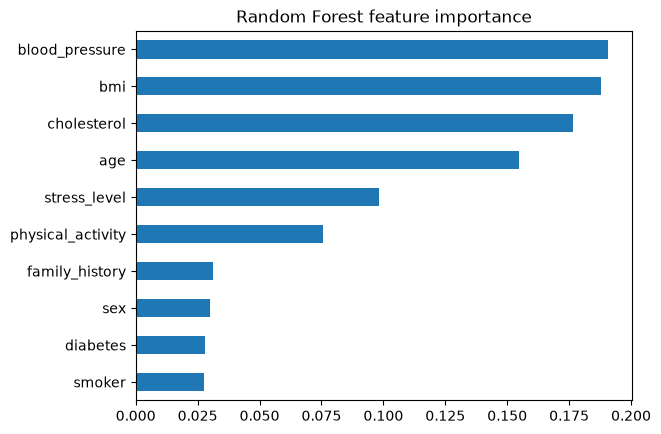

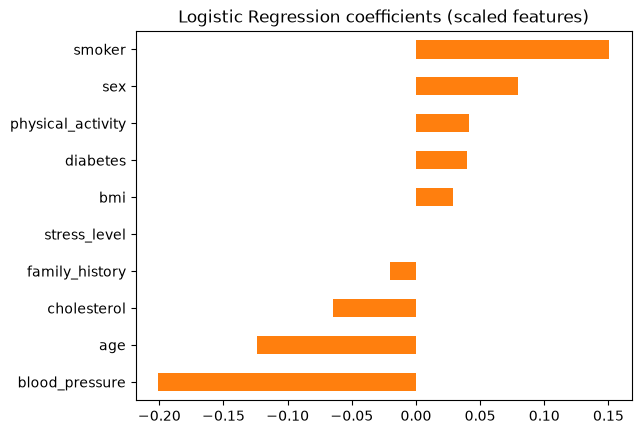

In [12]:
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(); plt.title('Random Forest feature importance'); plt.show()
coef = pd.Series(models['Logistic Regression'][-1].coef_[0], index=X.columns).sort_values()
coef.plot.barh(color='tab:orange'); plt.title('Logistic Regression coefficients (scaled features)'); plt.show()

## 8. Is there any real signal? A statistical check
All three models scored an AUC close to **0.5** (coin-flip level), even with cross-validation. Before blaming the models, check the data itself: does any feature differ between patients with and without heart disease more than chance would explain?
- numeric features → **Welch t-test** (difference in means)
- Yes/No features → **chi-square test** (difference in proportions)
- **p < 0.05** would suggest a real relationship.

In [13]:
from scipy import stats
rows = []
for c in num_cols:
    a, b = df.loc[df.heart_disease == 1, c], df.loc[df.heart_disease == 0, c]
    rows.append({'feature': c, 'test': 't-test', 'mean (disease)': round(a.mean(), 2), 'mean (no disease)': round(b.mean(), 2),
                 'p_value': round(stats.ttest_ind(a, b, equal_var=False).pvalue, 3)})
for c in cat_cols:
    rows.append({'feature': c, 'test': 'chi-square', 'p_value': round(stats.chi2_contingency(pd.crosstab(df[c], df.heart_disease))[1], 3)})
pd.DataFrame(rows)

,feature,test,mean (disease),mean (no disease),p_value
0,age,t-test,54.17,55.65,0.248
1,blood_pressure,t-test,131.21,134.76,0.135
2,cholesterol,t-test,221.87,221.08,0.842
3,bmi,t-test,29.22,28.79,0.453
4,physical_activity,t-test,2.12,1.97,0.252
5,stress_level,t-test,4.86,4.89,0.890
6,sex,chi-square,NaN,NaN,0.588
7,smoker,chi-square,NaN,NaN,0.048
8,diabetes,chi-square,NaN,NaN,0.776
9,family_history,chi-square,NaN,NaN,1.000


In [14]:
# Permutation check: shuffle the labels and retrain. If real-label AUC is no better than shuffled-label AUC, the features carry no signal.
from sklearn.model_selection import permutation_test_score
score, perm_scores, p = permutation_test_score(models['Logistic Regression'], X, y, scoring='roc_auc',
                                               cv=cv, n_permutations=100, random_state=RANDOM_STATE)
print(f'Real-label AUC = {score:.3f};  shuffled-label AUC = {perm_scores.mean():.3f} ± {perm_scores.std():.3f};  p = {p:.3f}')

Real-label AUC = 0.507;  shuffled-label AUC = 0.500 ± 0.039;  p = 0.446


## 9. Conclusion
**Results:** Logistic Regression, Random Forest and Gradient Boosting all reached a test **AUC of about 0.50–0.57** and accuracy of about **53–56 %**; 5-fold cross-validation gave AUC ≈ **0.50–0.54**. The majority class (heart disease = 1) is 53 % of patients, so the models barely beat "always predict 1".

**Why:** the statistical tests above show that nine of the ten risk factors do not differ between patients with and without heart disease (p from 0.14 to 1.0). Only **smoking** is borderline (p = 0.048: 58 % of smokers vs 48 % of non-smokers have the label) — but when 10 tests are run, one p-value under 0.05 is expected by chance alone; with a Bonferroni correction the threshold becomes 0.05 / 10 = 0.005, which smoking does not pass. The **permutation test** confirms it: real-label AUC 0.507 vs shuffled-label AUC 0.500 (p = 0.45), i.e. the models do no better with the real labels than with random ones. In this synthetic dataset the **heart_disease label appears to be generated independently of the features** — there is no pattern for any model to learn. The threshold table shows the same thing: moving the threshold only trades recall against false alarms almost one-for-one, which is what a diagonal (random) ROC curve looks like.

**Lessons:**
1. A model can only learn patterns that exist in the data — *garbage in, garbage out*. Model choice cannot fix data with no signal.
2. Accuracy alone would have hidden this (56 % sounds like "something"); **AUC, the confusion matrix and a permutation test expose it**.
3. In a real hospital, age, blood pressure, cholesterol, smoking, diabetes and family history *are* known risk factors, so a real dataset would be expected to give a much higher AUC. Next steps: collect real (anonymised) records, or check how the synthetic data was generated.